In [2]:
import h5py

path = r"../dataset/MIT_LFP_DS/2017-05-12_batchdata_updated_struct_errorcorrect.mat"
f = h5py.File(path, "r")     

print(list(f.keys()))    
print(list(f["batch"].keys())) 

['#refs#', '#subsystem#', 'batch', 'batch_date']
['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']


In [3]:
import numpy as np

n_cells = f["batch"]["cycle_life"].shape[0]
print("Number of cells:", n_cells)

ref = f["batch"]["cycle_life"][0, 0]   
cycle_life = f[ref][()]                
print("Cell 0 cycle life:", cycle_life)


ref = f["batch"]["policy_readable"][0, 0]
policy = "".join(chr(c) for c in f[ref][()].flatten())
print("Cell 0 policy:", policy)

Number of cells: 46
Cell 0 cycle life: [[1190.]]
Cell 0 policy: 3.6C(80%)-3.6C


In [4]:
import pandas as pd

ref = f["batch"]["summary"][0, 0]
s = f[ref]                     
print("Fields:", list(s.keys()))


cell0 = pd.DataFrame({key: s[key][()].flatten() for key in s.keys()})
print(cell0.shape)               
cell0.head()

Fields: ['IR', 'QCharge', 'QDischarge', 'Tavg', 'Tmax', 'Tmin', 'chargetime', 'cycle']
(1189, 8)


,IR,QCharge,QDischarge,Tavg,Tmax,Tmin,chargetime,cycle
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
1,0.016742,1.071042,1.070689,31.875011,35.652016,29.566130,13.341250,2.0
2,0.016724,1.071674,1.071900,31.931490,35.692978,29.604385,13.425777,3.0
3,0.016681,1.072304,1.072510,31.932603,35.680588,29.744202,13.425167,4.0
4,0.016662,1.072970,1.073174,31.959322,35.728691,29.644709,13.341442,5.0


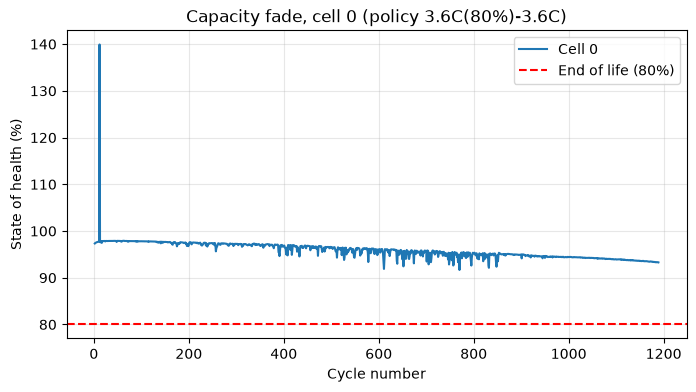

       cycle  QDischarge        SOH        IR
1183  1185.0    1.026472  93.315636  0.017084
1184  1186.0    1.026700  93.336364  0.017078
1185  1187.0    1.026499  93.318055  0.017085
1186  1188.0    1.026677  93.334255  0.017072
1187  1189.0    1.026210  93.291800  0.017089


In [5]:
import matplotlib.pyplot as plt

cell0 = cell0[cell0["QDischarge"] > 0].reset_index(drop=True)   
cell0["SOH"] = cell0["QDischarge"] / 1.1 * 100              

plt.figure(figsize=(8, 4))
plt.plot(cell0["cycle"], cell0["SOH"], label="Cell 0")
plt.axhline(80, color="red", linestyle="--", label="End of life (80%)")
plt.xlabel("Cycle number")
plt.ylabel("State of health (%)")
plt.title("Capacity fade, cell 0 (policy 3.6C(80%)-3.6C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(cell0[["cycle", "QDischarge", "SOH", "IR"]].tail())

Removed 129 outlier cycles out of 1188


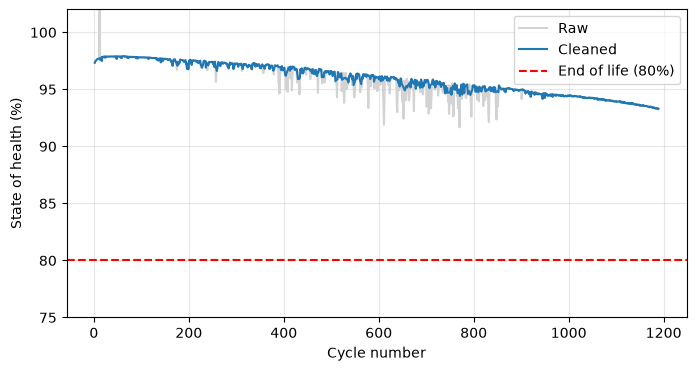

Resistance at start: 0.01663 ohm
Resistance at end:   0.01711 ohm


In [7]:
# median of the 11 neighbouring cycles around each point
trend = cell0["SOH"].rolling(window=11, center=True, min_periods=1).median()


ok = (cell0["SOH"] - trend).abs() < 0.5
clean0 = cell0[ok].reset_index(drop=True)
print(f"Removed {(~ok).sum()} outlier cycles out of {len(cell0)}")

plt.figure(figsize=(8, 4))
plt.plot(cell0["cycle"], cell0["SOH"], color="lightgray", label="Raw")
plt.plot(clean0["cycle"], clean0["SOH"], label="Cleaned")
plt.axhline(80, color="red", linestyle="--", label="End of life (80%)")
plt.ylim(75, 102)
plt.xlabel("Cycle number"); plt.ylabel("State of health (%)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Resistance at start:", round(clean0["IR"].iloc[:10].mean(), 5), "ohm")
print("Resistance at end:  ", round(clean0["IR"].iloc[-10:].mean(), 5), "ohm")

(38627, 11)


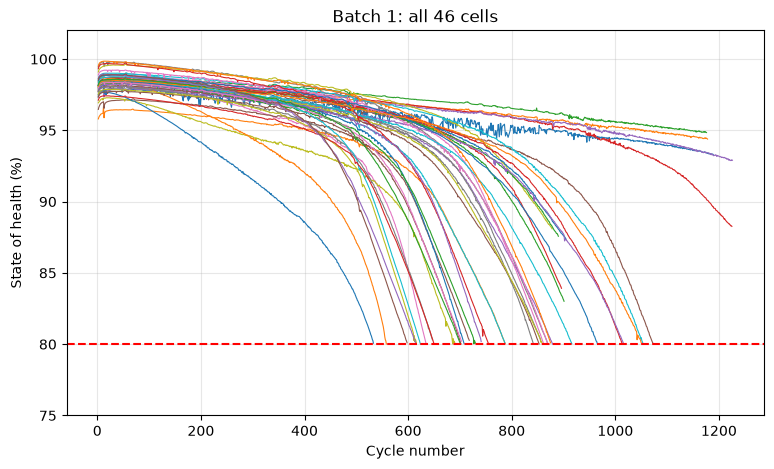

Cells that reached 80% in this file: 0 of 46


In [8]:
def load_cell(i):
    """Read, clean and return the summary table for cell i."""
    s = f[f["batch"]["summary"][i, 0]]
    df = pd.DataFrame({k: s[k][()].flatten() for k in s.keys()})
    df = df[df["QDischarge"] > 0].reset_index(drop=True)       # drop empty setup row
    df["SOH"] = df["QDischarge"] / 1.1 * 100
    trend = df["SOH"].rolling(11, center=True, min_periods=1).median()
    df = df[(df["SOH"] - trend).abs() < 0.5].reset_index(drop=True)  # remove outliers
    df["cell"] = i
    df["cycle_life"] = float(f[f["batch"]["cycle_life"][i, 0]][()].item())
    return df

cells = [load_cell(i) for i in range(n_cells)]
data = pd.concat(cells, ignore_index=True)    # one big table, all cells
print(data.shape)

plt.figure(figsize=(9, 5))
for df in cells:
    plt.plot(df["cycle"], df["SOH"], linewidth=0.8)
plt.axhline(80, color="red", linestyle="--")
plt.ylim(75, 102)
plt.xlabel("Cycle number"); plt.ylabel("State of health (%)")
plt.title("Batch 1: all 46 cells")
plt.grid(alpha=0.3); plt.show()

reached = [df["cell"].iloc[0] for df in cells if df["SOH"].min() < 80]
print("Cells that reached 80% in this file:", len(reached), "of", n_cells)

Cells used: 36


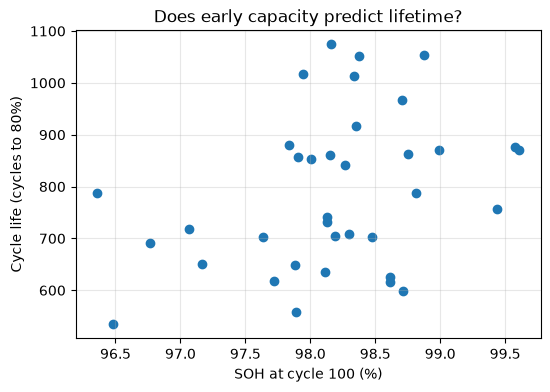

Correlation: 0.34


In [11]:
rows = []
for df in cells:
    if df["SOH"].min() > 81:        # never got close to 80%: lifetime not measured here
        continue
    near100 = df[(df["cycle"] >= 95) & (df["cycle"] <= 105)]
    rows.append({"cell": df["cell"].iloc[0],
                 "SOH_at_100": near100["SOH"].mean(),
                 "life": df["cycle_life"].iloc[0]})
early = pd.DataFrame(rows)
print("Cells used:", len(early))     # check this BEFORE plotting

plt.figure(figsize=(6, 4))
plt.scatter(early["SOH_at_100"], early["life"])
plt.xlabel("SOH at cycle 100 (%)"); plt.ylabel("Cycle life (cycles to 80%)")
plt.title("Does early capacity predict lifetime?")
plt.grid(alpha=0.3); plt.show()

print("Correlation:", round(early["SOH_at_100"].corr(early["life"]), 2))

In [12]:
import os
os.makedirs("processed", exist_ok=True)
data.to_csv("processed/batch1_summary_clean.csv", index=False)
print("Saved", data.shape, "to processed/batch1_summary_clean.csv")

Saved (38627, 11) to processed/batch1_summary_clean.csv


cell 20: life=534, variance of ΔQ = 4.33e-04, log10(var) = -3.36
cell 5: life=1074, variance of ΔQ = 6.99e-05, log10(var) = -4.16


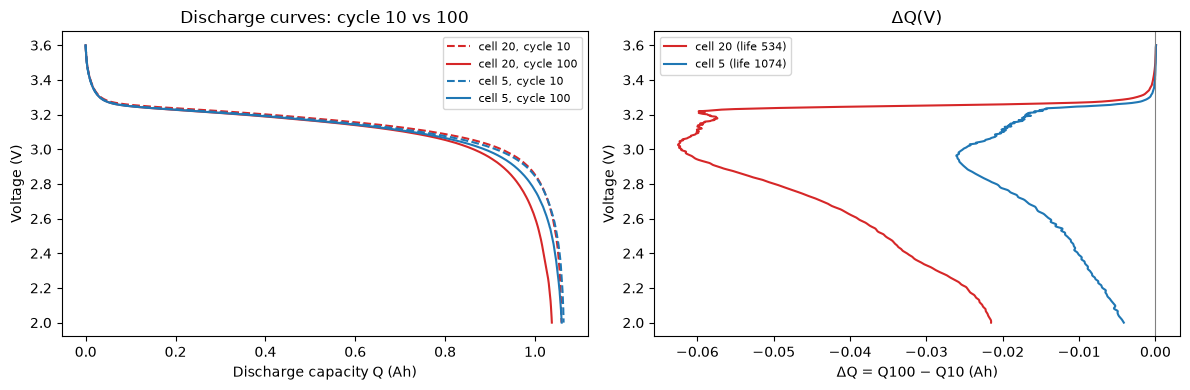

In [13]:
def get_qdlin(i, j):
    """Discharge capacity on the fixed voltage grid, for cell i, cycle j."""
    cyc = f[f["batch"]["cycles"][i, 0]]
    return f[cyc["Qdlin"][j, 0]][()].flatten()

V = np.linspace(3.6, 2.0, 1000)            # the voltage grid Qdlin is stored on

order = early.sort_values("life")
short = int(order.iloc[0]["cell"]);  short_life = int(order.iloc[0]["life"])
long_ = int(order.iloc[-1]["cell"]); long_life  = int(order.iloc[-1]["life"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, life, col in [(short, short_life, "tab:red"), (long_, long_life, "tab:blue")]:
    q10, q100 = get_qdlin(i, 10), get_qdlin(i, 100)
    ax[0].plot(q10, V, color=col, linestyle="--", label=f"cell {i}, cycle 10")
    ax[0].plot(q100, V, color=col, label=f"cell {i}, cycle 100")
    dq = q100 - q10
    ax[1].plot(dq, V, color=col, label=f"cell {i} (life {life})")
    print(f"cell {i}: life={life}, variance of ΔQ = {np.var(dq):.2e}, "
          f"log10(var) = {np.log10(np.var(dq)):.2f}")

ax[0].set_xlabel("Discharge capacity Q (Ah)"); ax[0].set_ylabel("Voltage (V)")
ax[0].set_title("Discharge curves: cycle 10 vs 100"); ax[0].legend(fontsize=8)
ax[1].axvline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("ΔQ = Q100 − Q10 (Ah)"); ax[1].set_ylabel("Voltage (V)")
ax[1].set_title("ΔQ(V)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


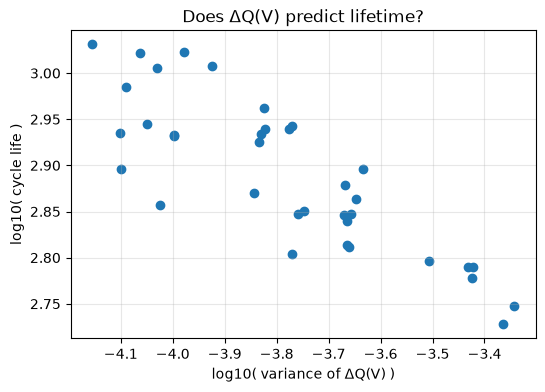

Correlation, ΔQ feature: -0.84
Correlation, SOH at 100 (from before): 0.34


In [14]:
feat = []
for _, row in early.iterrows():
    i = int(row["cell"])
    dq = get_qdlin(i, 100) - get_qdlin(i, 10)
    feat.append({"cell": i,
                 "life": row["life"],
                 "SOH_at_100": row["SOH_at_100"],
                 "log_var_dQ": np.log10(np.var(dq))})
feat = pd.DataFrame(feat)

plt.figure(figsize=(6, 4))
plt.scatter(feat["log_var_dQ"], np.log10(feat["life"]))
plt.xlabel("log10( variance of ΔQ(V) )"); plt.ylabel("log10( cycle life )")
plt.title("Does ΔQ(V) predict lifetime?")
plt.grid(alpha=0.3); plt.show()

print("Correlation, ΔQ feature:", round(feat["log_var_dQ"].corr(np.log10(feat["life"])), 2))
print("Correlation, SOH at 100 (from before):", round(feat["SOH_at_100"].corr(feat["life"]), 2))

Average error: 8.8%   (worst cell: 29.3%)


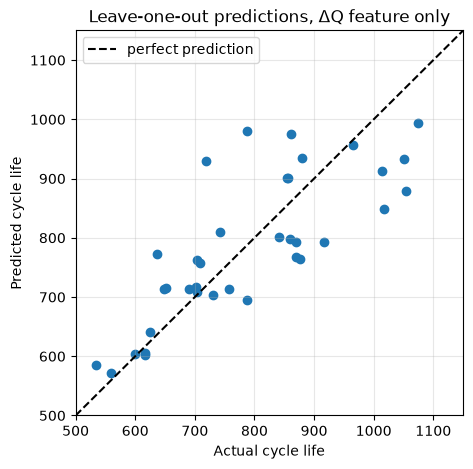

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

X = feat[["log_var_dQ"]].values          
y = np.log10(feat["life"].values)        

pred_log = cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut())
pred_life = 10 ** pred_log               

err = np.abs(pred_life - feat["life"]) / feat["life"] * 100
print(f"Average error: {err.mean():.1f}%   (worst cell: {err.max():.1f}%)")

plt.figure(figsize=(5, 5))
plt.scatter(feat["life"], pred_life)
lims = [500, 1150]
plt.plot(lims, lims, "k--", label="perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual cycle life"); plt.ylabel("Predicted cycle life")
plt.title("Leave-one-out predictions, ΔQ feature only")
plt.legend(); plt.grid(alpha=0.3); plt.show()